[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Ghost on the Circuit

A dorm's electric bill is higher than usual, and building services wants to know why.
A power meter logs the average watts it draws each hour.
Additionally, all 150 devices on campus uses a smart-plug system which tells whether they were on (1) or off (0) each hour.
Our goal is to identify which of these devices were plugged in to the dorm.

We simulate one such dataset as: `circuit = GhostCircuit.sample(seed=0)` which gives 72 hours of smart-plug logs `circuit.x` (one row per hour, one column per device) and meter readings `circuit.y`.
Assume that each device draws the same power in every hour its on, though the power consumption is unique per device and unknown a priori.

Write `estimate(x, y)`, which returns the devices (column numbers of `x`) you believe are on the metered circuit.  Anything on a circuit whose name starts with an underscore (e.g. `circuit._on_circuit`) is the hidden truth: peeking at it is cheating.  

Summarize your approach and efficacy in the submitted ipynb file.  Give a TPR and FPR for detected devices on as you validate your method across many seeds.

For fun, post your `estimate` to the [leaderboard](https://matthigger.github.io/ml_puzzle/ghost_circuit/) with class code `ghost-p3yt-rjx8-36ue` (no effect on your grade).


{'right': 3, 'wrong': 5, 'missed': 5, 'exact': False}


20 circuits: 3.6 of 8 devices found, 6.9 wrongly named, exactly right 0% of the time


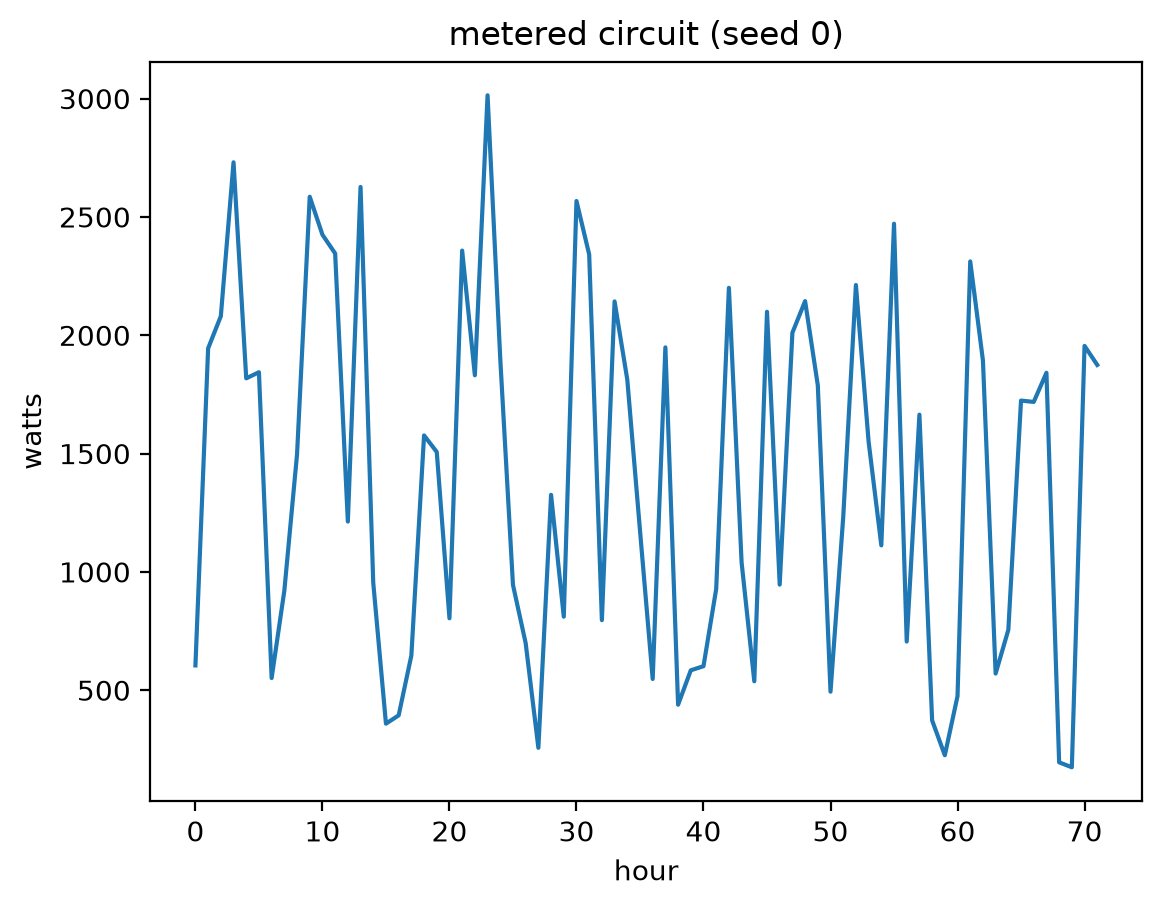

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ghost_circuit import GhostCircuit, evaluate

circuit = GhostCircuit.sample(seed=0)
x, y = circuit.x, circuit.y
plt.plot(y)
plt.xlabel('hour')
plt.ylabel('watts')
plt.title('metered circuit (seed 0)')


def correlated(x, y):
    """ every device whose on / off pattern correlates with the meter """
    r = np.array([np.corrcoef(x[:, i], y)[0, 1] for i in range(x.shape[1])])
    return np.where(r > .2)[0]


print(circuit.score(correlated(x, y)))
evaluate(correlated);

# Executive summary

We identified which of 150 devices feed the dorm's meter by matching each device's on/off schedule to the meter's ups and downs, adding devices only while each explains more of the bill. On 1,000 new simulated dorms, we named the devices behind 98% of the energy the dorm's devices used, while wrongly accusing one device per 37 dorms (a correlation check: 7 per dorm). We find almost every device over 100 watts but rarely those under 50, lost in the meter's noise; even a benchmark told 7 of the 8 answers does only slightly better. Twelve days of readings instead of three would find 95%.

# Approach

Model: meter = baseline + Σ watts × (on/off) + noise. **Forward stepwise least squares:** each step adds the device that most reduces squared error, among those with positive fitted watts. Stop when that addition fails an F-test at α = 0.05 / (devices remaining), Bonferroni-correcting for ~150 candidates. α is strict because false accusations trigger needless inspections; it was fixed before testing.

**Assumptions:** constant watts per device; independent device schedules; Gaussian noise; unknown device count.

**Result** (1,000 circuits never examined during development): TPR 77%, FPR 0.019% (95% range 0.013–0.028%). TPR: share of on-circuit devices named; FPR: share of off-circuit devices named. α is a setting; the measured FPR is the real error rate. Naming all 8 is rare (2%): each circuit has about one device under 35 W, found 4% of the time.


In [2]:
from ghost_circuit import OFFICIAL
from ghost_helper import (N_OFF, stepwise, correlated, validate, tradeoff,
                          oracle_curve, more_hours, plot_found_by_watts,
                          plot_tradeoff)

estimate = stepwise  # the requested estimate(x, y)

evaluate(estimate)  # the 20 official circuits
res = {f.__name__: validate(f) for f in [stepwise, correlated]}  # 1,000 unseen
for name, r in res.items():
    print(f"{name:>10}: TPR {r['tpr']:.1%}, FPR {r['fpr']:.3%} (95% range "
          f"{r['fpr_lo']:.3%} to {r['fpr_hi']:.3%}), {r['fpr'] * N_OFF:.3f} "
          f"wrongly named per circuit, {r['energy']:.1%} of energy found")

20 circuits: 6.3 of 8 devices found, 0.1 wrongly named, exactly right 0% of the time


  stepwise: TPR 76.8%, FPR 0.019% (95% range 0.013% to 0.028%), 0.027 wrongly named per circuit, 97.6% of energy found
correlated: TPR 44.3%, FPR 4.704% (95% range 4.592% to 4.818%), 6.680 wrongly named per circuit, 82.7% of energy found


found 99.7% of devices over 100 W, 4% of devices under 35 W


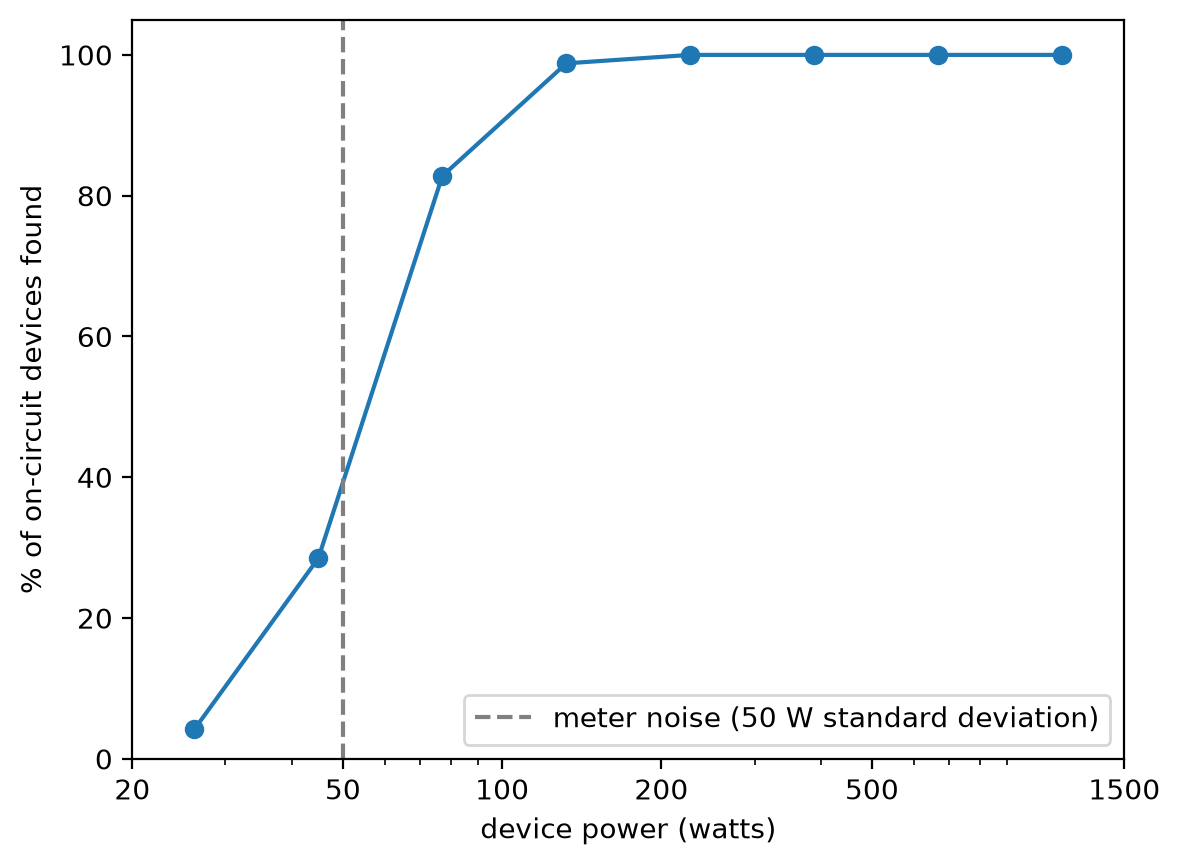

In [3]:
r = res['stepwise']
plot_found_by_watts(r, OFFICIAL['noise'])
print(f"found {r['found'][r['watts'] > 100].mean():.1%} of devices over 100 W, "
      f"{r['found'][r['watts'] < 35].mean():.0%} of devices under 35 W")

Devices over 100 W are almost always found; near and below the 50 W noise, most are missed.

alpha = 0.05: stepwise TPR 76.8%, benchmark 77.9%


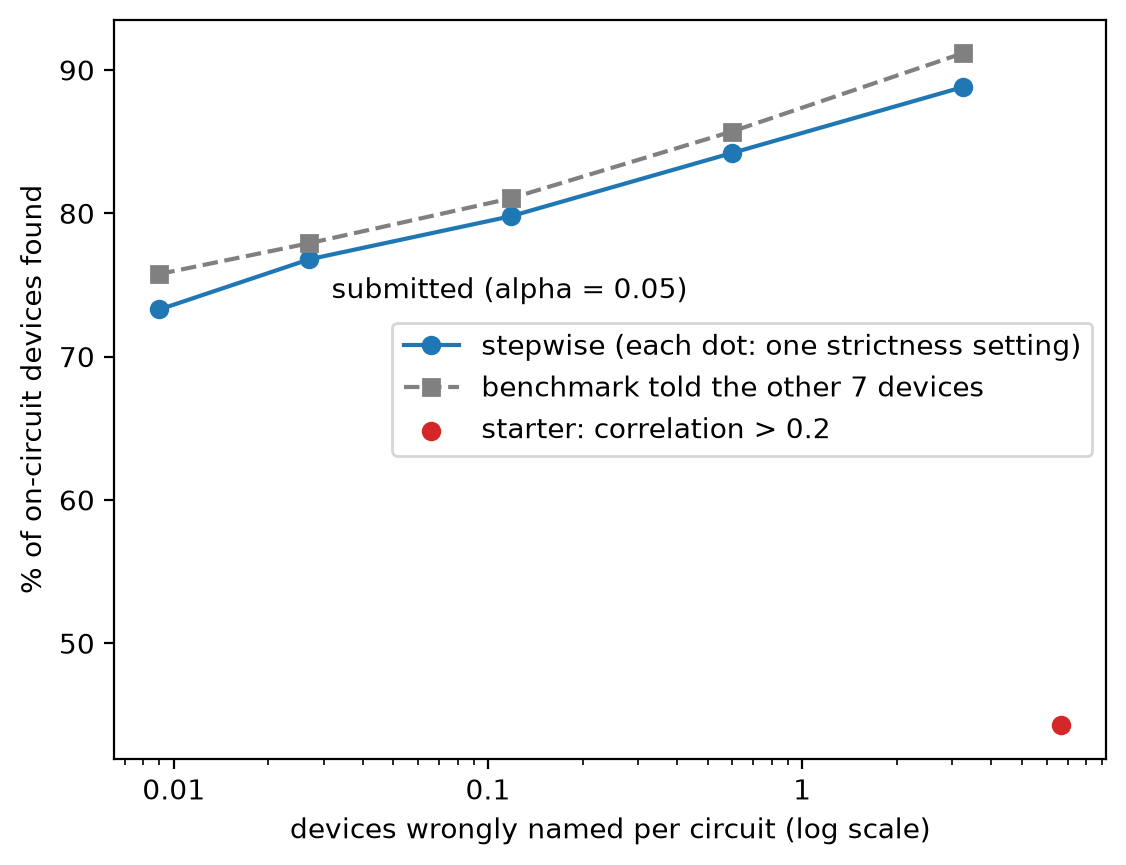

In [4]:
alphas = [.01, .05, .2, 1, 5]
curve = tradeoff(stepwise, alphas)  # (FPR, TPR) for each alpha
bench = oracle_curve(curve[:, 0])   # benchmark's TPR at the same FPRs
plot_tradeoff(curve, bench, res['correlated'], alphas)
print(f'alpha = 0.05: stepwise TPR {curve[1, 1]:.1%}, benchmark {bench[1]:.1%}')

Stepwise stays within 3 points of the benchmark at every setting and far ahead of the starter: misses are a data limit, not a method flaw.

In [5]:
for hours, tpr in more_hours(stepwise).items():
    print(f'{hours} hours ({hours // 24} days) of readings: TPR {tpr:.1%}')

72 hours (3 days) of readings: TPR 76.4%
144 hours (6 days) of readings: TPR 87.1%
288 hours (12 days) of readings: TPR 95.3%


More readings, not a cleverer method, find the small devices.